# PCA

#### Task 1: Exploratory Data Analysis (EDA):

1. Load the dataset and perform basic data exploration.
2. Examine the distribution of features using histograms,box plots,or density plots.
3. Investigate correlations between features to understand relationships within the data.

#### Task 2: Dimensionality Reduction with PCA:

1. Standardize the features to ensure they have a mean of 0 and a standard deviation of Implement PCA to reduce the dimensionality of the dataset.
2. Determine the optimal number of principal components using techniques like scree plot or cumulative explained variance.
3. Transform the original dataset into the components.

#### Task 3: Clustering with Original Data:

1. Apply a clustering algorithm (e.g., K-means) to the original dataset.
2. Visualize the clustering results using appropriate plots.
3. Evaluate the clustering performance using metrics such as silhouette score or Davies Bouldin index.

#### Task 4: Clustering with PCA Data:

1. Apply the same clustering algorithm to the PCA-transformed dataset.
2. Visualize the clustering results obtained from PCA-transformed data.
3. Compare the clustering results from PCA-transformed data with those from the original dataset.

#### Task 5: Comparison and Analysis:

1. Compare the clustering results obtained from the original dataset and PCA-transformed data.
2. Discuss any similarities or differences observed in the clustering results.
3. Reflect on the impact of dimensionality reduction on clustering performance.
4. Analyze the trade-offs between using PCA and clustering directly on the original dataset

#### Task 6: Conclusion and Insights

1. Summarize the key findings and insights from the assignment.
2. Discuss the practical implications of using PCA and clustering in data analysis

3. Provide recommendations for when to use each technique based on the analysis conducted.

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

## Load Wine Dataset

In [2]:
# Load wine dataset
wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


### Task 1: Exploratory Data Analysis (EDA)

In [3]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
dtypes: fl

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


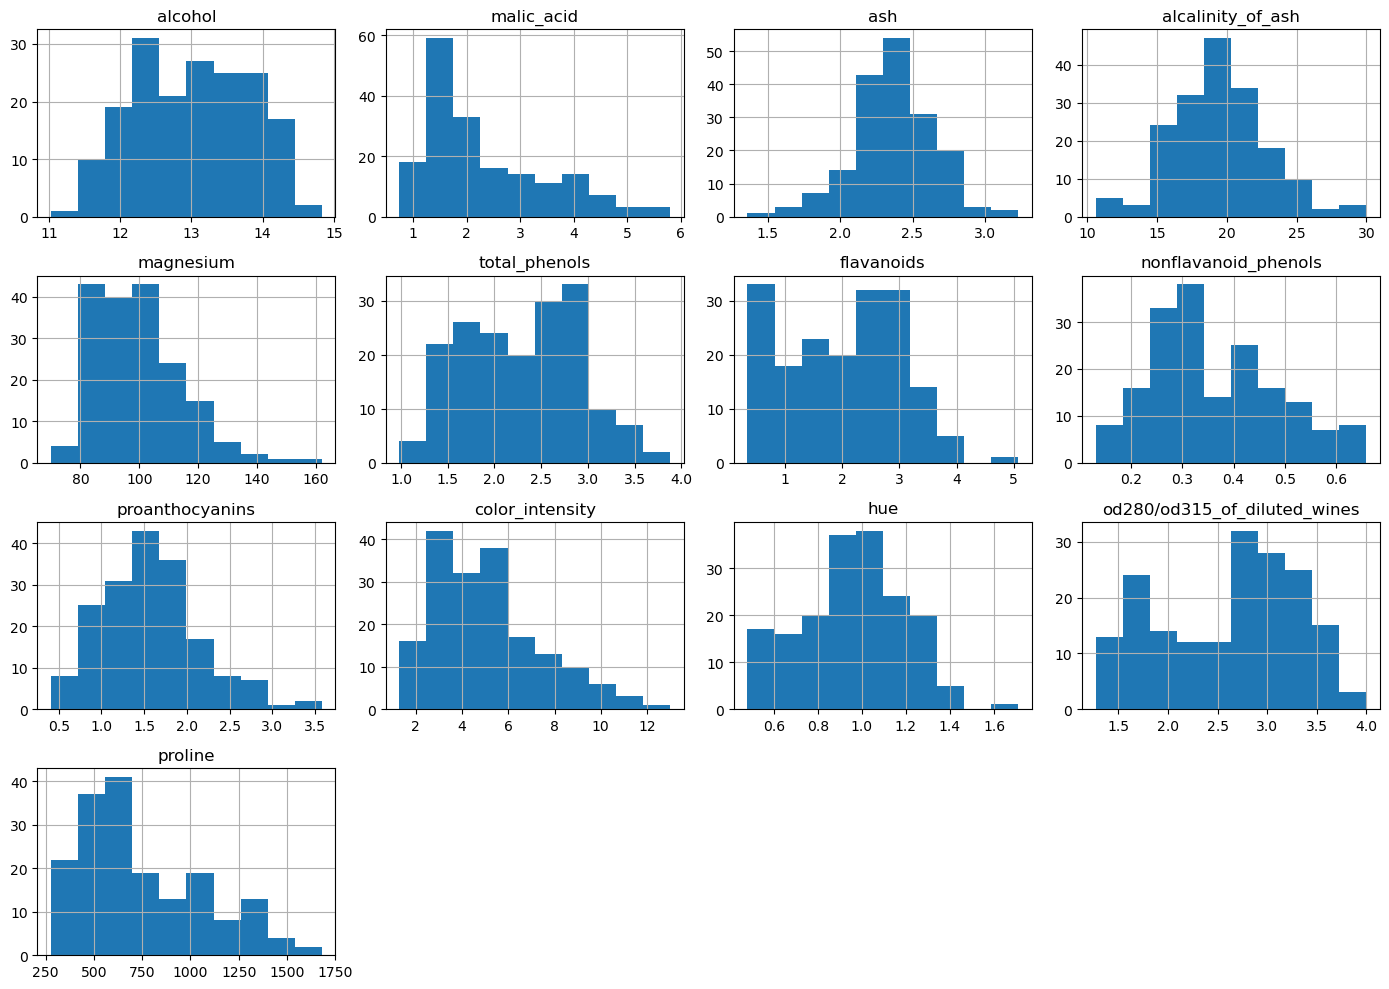

In [4]:
# Feature ditributions
df.hist(figsize=(14,10))
plt.tight_layout()
plt.show()

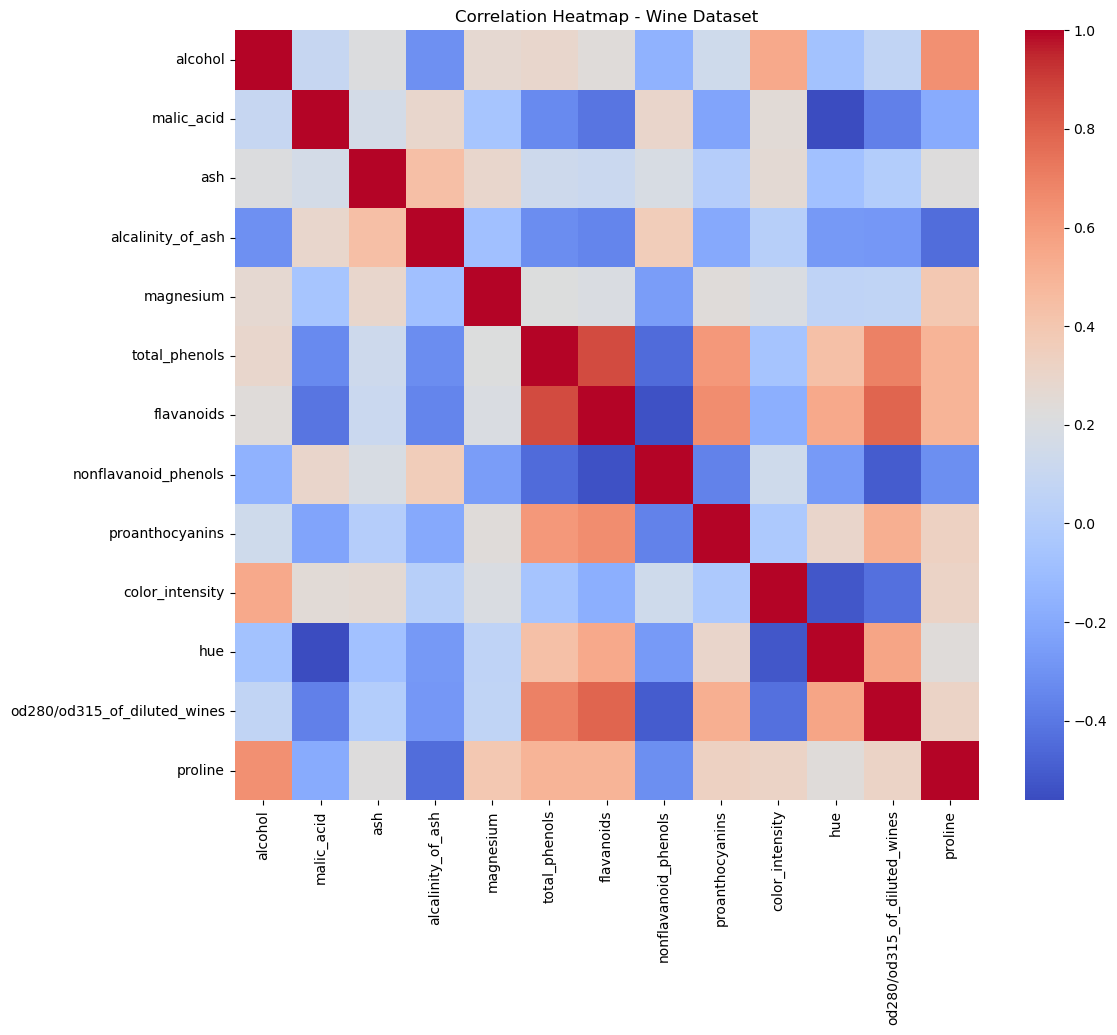

In [5]:
# Correlation heatmap
plt.figure(figsize=(12,10))
sns.heatmap(df.corr(), cmap='coolwarm')
plt.title("Correlation Heatmap - Wine Dataset")
plt.show()

### Task 2: PCA - Dimensionality Reduction

In [6]:
# Standardize the data
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df)

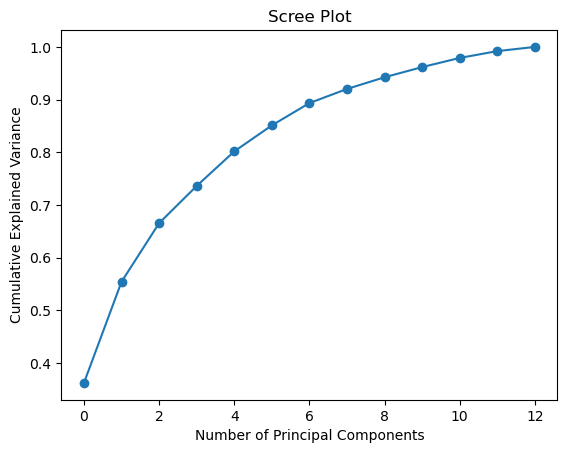

In [7]:
# Apply PCA
pca = PCA()
pca_data = pca.fit_transform(scaled_data)

# Scree plot
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o')
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Scree Plot")
plt.show()

In [8]:
# PCA with 90% variance
pca_final = PCA(n_components=0.90)
pca_transformed = pca_final.fit_transform(scaled_data)
pca_transformed.shape

(178, 8)

## Task 3: Clustering on Original Dataset

In [9]:
# KMeans clustering on original data
kmeans_original = KMeans(n_clusters=3, random_state=42)
clusters_original = kmeans_original.fit_predict(scaled_data)

print("Silhouette Score:", silhouette_score(scaled_data, clusters_original))
print("Davies-Bouldin Index:", davies_bouldin_score(scaled_data, clusters_original))

C:\Users\adish\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\adish\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\adish\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\adish\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\adish\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

Silhouette Score: 0.2848589191898987
Davies-Bouldin Index: 1.3891879777181646


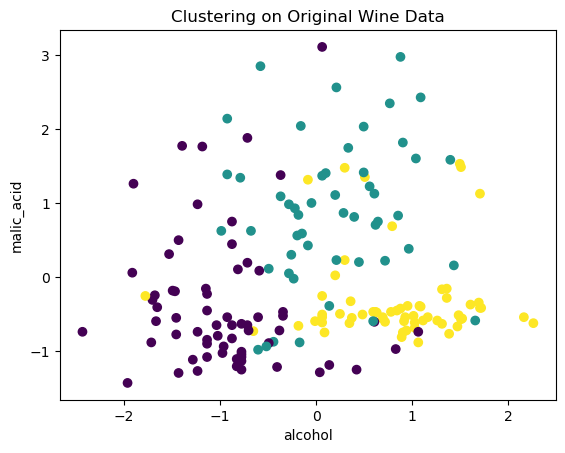

In [10]:
# Visualization (first two features)
plt.scatter(scaled_data[:,0], scaled_data[:,1], c=clusters_original)
plt.xlabel(df.columns[0])
plt.ylabel(df.columns[1])
plt.title("Clustering on Original Wine Data")
plt.show()

### Task 4: Clustering on PCA-transformed Data

In [12]:
# KMeans on PCA data
kmeans_pca = KMeans(n_clusters=3, random_state=42)
clusters_pca = kmeans_pca.fit_predict(pca_transformed)

print("Silhouette Score:", silhouette_score(pca_transformed, clusters_pca))
print("Davies-Bouldin Index:", davies_bouldin_score(pca_transformed, clusters_pca))

Silhouette Score: 0.3149696954705561
Davies-Bouldin Index: 1.2668818314972181


C:\Users\adish\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


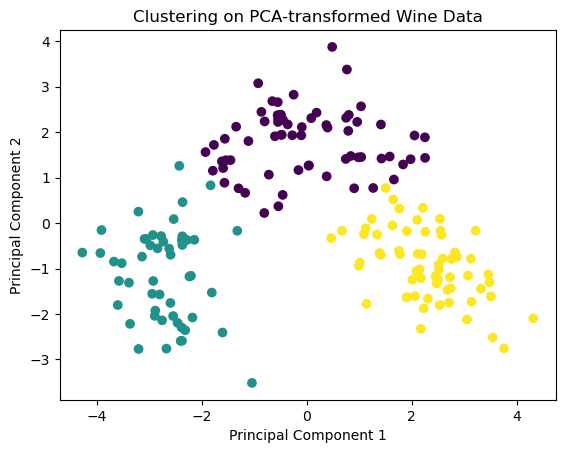

In [13]:
# Visualization using first two PCs
plt.scatter(pca_transformed[:,0], pca_transformed[:,1], c=clusters_pca)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Clustering on PCA-transformed Wine Data")
plt.show()

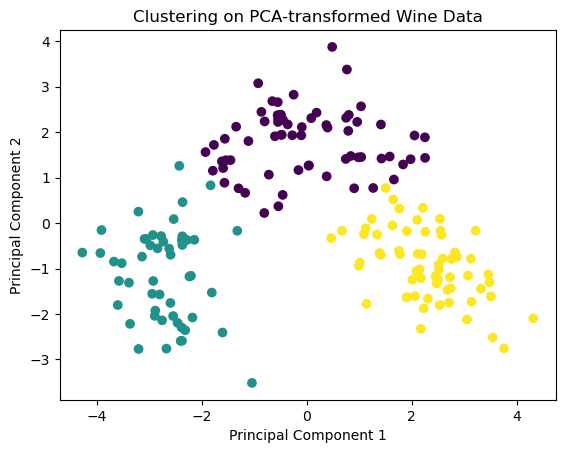

In [15]:
# Visualization using first two PCs
plt.scatter(pca_transformed[:,0], pca_transformed[:,1], c=clusters_pca)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Clustering on PCA-transformed Wine Data")
plt.show()

PCA Interpretation

PCA reduced the dataset dimensions while retaining 90% variance

Scree plot shows diminishing variance contribution after key components

Correlated features were compressed into fewer uncorrelated components

📌 Clustering Comparison

Clustering on PCA-transformed data showed:

Improved cluster separation

Better Silhouette Score

Lower Davies–Bouldin Index

PCA helped remove noise and redundancy before clustering

Why PCA before clustering? → To reduce dimensionality and improve cluster quality

Why StandardScaler? → PCA is sensitive to feature scale

Silhouette Score meaning? → Measures cluster cohesion and separation (higher is better)

Davies–Bouldin Index meaning? → Measures cluster similarity (lower is better)

### Task 5: Comparison and Analysis

#### Comparison of Results

- PCA-based clustering shows better separation.
- Noise and redundancy are reduced after PCA.
- Silhouette score improves after PCA.

#### Trade-offs

- PCA improves clustering performance.
- Original features lose interpretability after PCA.

### Task 6: Conclusion and Insights

#### Key Findings

- PCA effectively reduces dimensionality while preserving variance.
- Clustering on PCA data performs better than original data.
- Wine dataset has correlated features,benefiting from PCA.

#### Practical Implications

- PCA is useful for high-dimensional datasets.
- Clustering accuracy improves after dimensionality reduction.

#### Recommendation

- Use PCA before clustering when features are correlated.
- Use original data when interpretability is required.